In [92]:
# imports

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, AIMessage
from langchain_core.tools import tool
#-------------------------------------------------------------
from typing import Annotated, TypedDict
import operator
from langgraph.graph import START, END, StateGraph, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
#-------------------------------------------------------------
from IPython.display import Image
#-------------------------------------------------------------
from pydantic import BaseModel, Field
import os
from dotenv import load_dotenv

In [93]:
load_dotenv()

llm = ChatOpenAI(
    model="openai/gpt-oss-20b",
    api_key=os.getenv("OPENAI_API_KEY"),
    temperature=0.0,
    base_url="https://api.groq.com/openai/v1"
)

# Part 1 - Researcher Graph

In [94]:
# State
class ResearcherState(MessagesState):
    task: str
    research: str
    trace: Annotated[list[str], operator.add]

In [95]:
# tools
import wikipediaapi

wiki = wikipediaapi.Wikipedia(user_agent="langgraph-assignment/1.0 (student@example.com)")

@tool
def search_wikipedia(query: str) -> str:
    """Searches Wikipedia for the given query and returns a summary of the top result."""
    results = wiki.search(query, limit=3)

    output = []
    for title , page in results.pages.items():
        if page.exists():
            output.append(f"Title: {title}\nSummary: {page.summary[0:500]}...\nURL: {page.fullurl}")

    return "\n\n".join(output) if output else "No results found."

tools = [search_wikipedia]
llm_with_research_tools = llm.bind_tools(tools)

In [96]:
# nodes
def researcher_node(state: ResearcherState) -> dict:
    task = state["task"]
    system_message = SystemMessage(
        f"You are a helpful research assistant. You have been given the following task: '{task}'.\n"
        "First, identify the core subject or entity from this task (for example, if the task is 'Write a slogan for a coffee shop', the core subject is 'coffee shop').\n"
        "Then, gather RAW information on that specific subject using the available tools.\n"
        "Call the search tool EXACTLY ONCE using only the core subject as your query. After you receive the search results, DO NOT call any more tools."
        "Do not summarize or format the output. Just output the exact raw notes you received and finish."
    )
    response = llm_with_research_tools.invoke([
        system_message,
        *state["messages"]
    ])

    return {
        "research": response.content, 
        "messages": [response],
        "trace": ["researcher"]
    }
    

In [97]:
# graph
researcher = StateGraph(ResearcherState)
researcher.add_node("researcher", researcher_node)
researcher.add_node("tools", ToolNode(tools))

researcher.add_edge(START, "researcher")
researcher.add_conditional_edges("researcher", tools_condition)
researcher.add_edge("tools", "researcher")

researcher_app = researcher.compile()

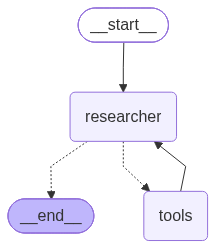

In [71]:
Image(researcher_app.get_graph().draw_mermaid_png())

In [ ]:
res = researcher_app.invoke(ResearcherState(task="Egyptian Pyramids"), {"recursion_limit": 5})
for message in res["messages"]:
    message.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  search_wikipedia (fc_645d1382-f4d7-40b9-a62c-a7cf4fa59960)
 Call ID: fc_645d1382-f4d7-40b9-a62c-a7cf4fa59960
  Args:
    query: Egyptian Pyramids
================================= Tool Message =================================
Name: search_wikipedia

Title: Egyptian pyramids
Summary: The Egyptian pyramids are ancient masonry structures located in Egypt. Most were built as tombs for the pharaohs and their consorts during the Old and Middle Kingdom periods. At least 138 identified pyramids have been discovered in Egypt. Approximately 80 pyramids were built within the Kingdom of Kush, now located in the modern country of Sudan.
The earliest known Egyptian pyramids are at Saqqara, west of Memphis. Step-pyramid-like structures, like Mastaba 3808 attributed to pharaoh Anedjib, may...
URL: https://en.wikipedia.org/wiki/Egyptian_pyramids

Title: Construction of the Egyptian pyramids
Summary: The cons

In [38]:
print(res.get("trace"))

['researcher', 'researcher']


In [39]:
print(res.get("research"))

Title: Egyptian pyramids  
Summary: The Egyptian pyramids are ancient masonry structures located in Egypt. Most were built as tombs for the pharaohs and their consorts during the Old and Middle Kingdom periods. At least 138 identified pyramids have been discovered in Egypt. Approximately 80 pyramids were built within the Kingdom of Kush, now located in the modern country of Sudan.  
The earliest known Egyptian pyramids are at Saqqara, west of Memphis. Step-pyramid-like structures, like Mastaba 3808 attributed to pharaoh Anedjib, may...  
URL: https://en.wikipedia.org/wiki/Egyptian_pyramids  

Title: Construction of the Egyptian pyramids  
Summary: The construction of the Egyptian pyramids can be explained with well-established scientific facts; however, there are some aspects that even today are considered controversial hypotheses. The construction techniques used seem to have developed over time; later pyramids were not constructed in the same way as earlier ones. It is believed that 

# part 2 - Writer Graph

In [98]:
# State
class WriterState(ResearcherState):
    feedback: str
    draft: str
    attempts: int

In [99]:
# nodes
def writer_node(state: WriterState) -> dict:
    research = state["research"]
    task = state["task"]
    feedback = state["feedback"]
    draft = state["draft"]
    attempts = state["attempts"]

    if research:
        system_message = SystemMessage(
            f"You are a helpful writer. write a draft on {task}."
            f"use the following research as raw source material:\n\n{research}."
        )
    else:
        system_message = SystemMessage(
            f"You are a helpful writer. write a draft on {task}."
        )
        
    if draft and feedback:
        system_message = SystemMessage(
            f"improve this draft --> {draft}.\n"
            f"use the following feedback to as revision guidance to improve the draft:\n\n{feedback}."
        )

    response = llm.invoke([
        system_message,
        *state["messages"]
    ])

    return {
        "draft": response.content,
        "attempts": attempts + 1,
        "messages": [response],
        "trace": ["writer"]
    }


In [100]:
writer = StateGraph(WriterState)
writer.add_node("writer", writer_node)

writer.add_edge(START, "writer")
writer.add_edge("writer", END)

writer_app = writer.compile()

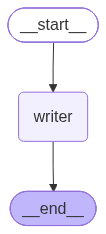

In [73]:
Image(writer_app.get_graph().draw_mermaid_png())

In [ ]:
res = writer_app.invoke(
    WriterState(
        task="Write a 3-sentence pitch for a plant-watering mobile app." ,
        research="",
        feedback="", draft="", attempts=0,
        messages=[], trace=[]))

In [25]:
res["draft"]

'**Draft Pitch (3 Sentences)**  \nMeet PlantPal, the mobile app that turns plant care into a breeze by sending you timely watering reminders tailored to each plant’s unique needs. With a simple tap, you can log waterings, track growth, and receive expert tips to keep your foliage healthy. Download PlantPal now and let your green companions thrive with minimal effort.'

In [26]:
res["attempts"]

1

In [27]:
res["trace"]

['writer']

# Part 3 - Reviewer Graph

In [101]:
# State
class ReviewerState(MessagesState):
    task: str
    draft: str
    feedback: str
    approved: bool
    trace: Annotated[list[str], operator.add]

In [102]:
class Review(BaseModel):
    feedback: str = Field(description="Specific, actionable feedback on the draft.")
    approved: bool = Field(description="True if the draft is good enough to publish.")

In [111]:
def reviewer_node(state: ReviewerState) -> dict:
    task = state["task"]
    draft = state["draft"]

    system_message = SystemMessage(
        f"You are a helpful reviewer. Review the following draft on {task}:\n\n{draft}.\n\n"
        "Provide specific, actionable feedback on how to improve the draft. "
        "Also indicate whether the draft is good enough to publish."
        "IMPORTANT: You must respond ONLY with valid JSON matching the requested schema. "
        "Do not include any conversational text, explanations, or markdown formatting like ```json."
    )

    structured_llm = llm.with_structured_output(Review)

    response = structured_llm.invoke([
        system_message,
        *state["messages"]
    ])

    return {
        "feedback": response.feedback,
        "approved": response.approved,
        "messages":  [AIMessage(content=response.feedback)],
        "trace": ["reviewer"]
    }

In [112]:
reviewer = StateGraph(ReviewerState)
reviewer.add_node("reviewer", reviewer_node)

reviewer.add_edge(START, "reviewer")
reviewer.add_edge("reviewer", END)

reviewer_app = reviewer.compile()

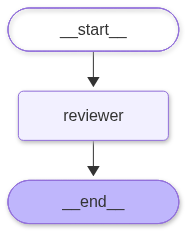

In [75]:
Image(reviewer_app.get_graph().draw_mermaid_png())

# Part 4 - Orchestration Layer

In [113]:
# State
class OrchestratorState(TypedDict):
    task: str
    research: str
    draft: str
    feedback: str
    approved: bool
    attempts: int
    trace: Annotated[list[str], operator.add]

In [114]:
# nodes
def run_researcher(state: OrchestratorState)-> dict:
    out = researcher_app.invoke(state)
    return {
    "research": out["research"],
    "trace": ["researcher"], 
    }

def run_writer(state: OrchestratorState)-> dict:
    out = writer_app.invoke(state)
    return {
    "draft": out["draft"],
    "attempts": out["attempts"],
    "trace": ["writer"],
    }

def run_reviewer(state: OrchestratorState)-> dict:
    out = reviewer_app.invoke(state)
    return {
    "feedback": out["feedback"],
    "approved": out["approved"],
    "trace": ["reviewer"],
    }


In [115]:
MAX_ATTEMPTS = 3
def route_after_review(state: OrchestratorState) -> str:
    if state["approved"] or state["attempts"] >= MAX_ATTEMPTS:
        return END
    else:
        return "writer"

In [116]:
orchestrator_app = StateGraph(OrchestratorState)
orchestrator_app.add_node("researcher", run_researcher)
orchestrator_app.add_node("writer", run_writer)
orchestrator_app.add_node("reviewer", run_reviewer)

orchestrator_app.add_edge(START, "researcher")
orchestrator_app.add_edge("researcher", "writer")
orchestrator_app.add_edge("writer", "reviewer")
orchestrator_app.add_conditional_edges("reviewer", route_after_review, [END, "writer"])

graph = orchestrator_app.compile()

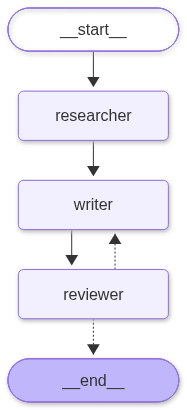

In [109]:
Image(graph.get_graph().draw_mermaid_png())

In [117]:
multi_agent_app = graph.invoke(OrchestratorState(
    task="Write a single-sentence slogan for a coffee shop. Keep it under 10 words.",
    research="", draft="", feedback="", approved=False,
    attempts=0, trace=[]
    )
)

In [118]:
print(f"research:\n{multi_agent_app['research']}\n\ndraft:\n{multi_agent_app['draft']}\n\napproved:\n{multi_agent_app['approved']}\n\nattempts:\n{multi_agent_app['attempts']}\n\ntrace:\n{multi_agent_app['trace']}")

research:
Title: Coffee shop
Summary: Coffee shop may refer to:...
URL: https://en.wikipedia.org/wiki/Coffee_shop

Title: Coffeehouse
Summary: A coffeehouse, coffee shop, or café, is an establishment that serves various types of coffee drinks like espresso, latte, americano, and cappuccino, as well as other beverages. An espresso bar specializes in serving espresso and espresso-based drinks. Some coffeehouses may serve iced coffee among other cold drinks, as well as non-caffeinated drinks. A coffeehouse may also serve food, such as light snacks, sandwiches, muffins, cakes, breads, pastries, or doughnuts. Many doughnut shops in Canada a...
URL: https://en.wikipedia.org/wiki/Coffeehouse

Title: Johnie's Coffee Shop
Summary: Johnie's Coffee Shop  is a former coffee shop and a well-known example of Googie architecture located on the corner of Wilshire Boulevard and Fairfax Avenue in Los Angeles, California. Architects Louis Armét and Eldon Davis of Armét & Davis designed the building, cont